<a href="https://colab.research.google.com/github/vsai4607/MLA0204/blob/main/program6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No

Actual Values: [1 1 0 1 0]
Predicted Values: [1 1 1 1 1]

Accuracy: 60.0 %

Confusion Matrix:
[[0 2]
 [0 3]]


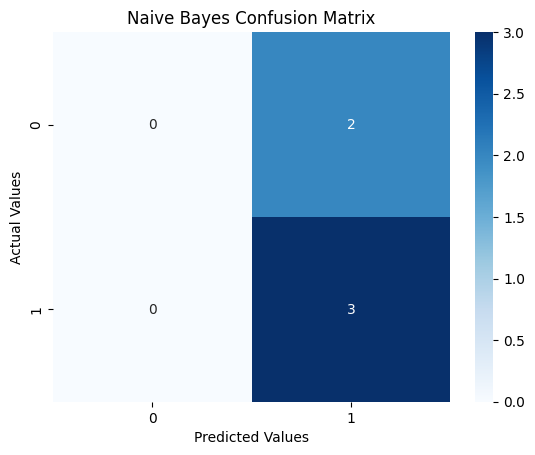

In [2]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, confusion_matrix

# Step 1: Load Excel dataset
data = pd.read_excel("tennis.xlsx")

print("Dataset:")
print(data)

# Step 2: Convert categorical values into numbers
le = LabelEncoder()

for column in data.columns:
    data[column] = le.fit_transform(data[column])

# Step 3: Separate input and output
X = data.drop("Play", axis=1)
y = data["Play"]

# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Step 5: Create and train Naive Bayes model
model = CategoricalNB()
model.fit(X_train, y_train)

# Step 6: Predict the results
y_pred = model.predict(X_test)

print("\nActual Values:", y_test.values)
print("Predicted Values:", y_pred)

# Step 7: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy * 100, "%")

# Step 8: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Step 9: Plot confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Naive Bayes Confusion Matrix")

plt.show()